In [1]:
# import dependencies
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Load data
food_deserts = gpd.read_file("data/lila_halfmi_census.shp")
biz_data = pd.read_excel("data/Atlanta_Business_License_Records_2025.xlsx")
biz_geo = gpd.GeoDataFrame(biz_data, geometry = gpd.points_from_xy(biz_data['latitude'], biz_data['longitude']), crs = 4326)
Aglanta = gpd.read_file("data/Aglanta_FFA_2025_ATL_Only.shp")
tax_parcels = gpd.read_file("data/Tax_Parcels_2025.shp")
NSA_w_demographoics = gpd.read_file("data/Official_NSAs_with_Current_Demographic_Data.shp")


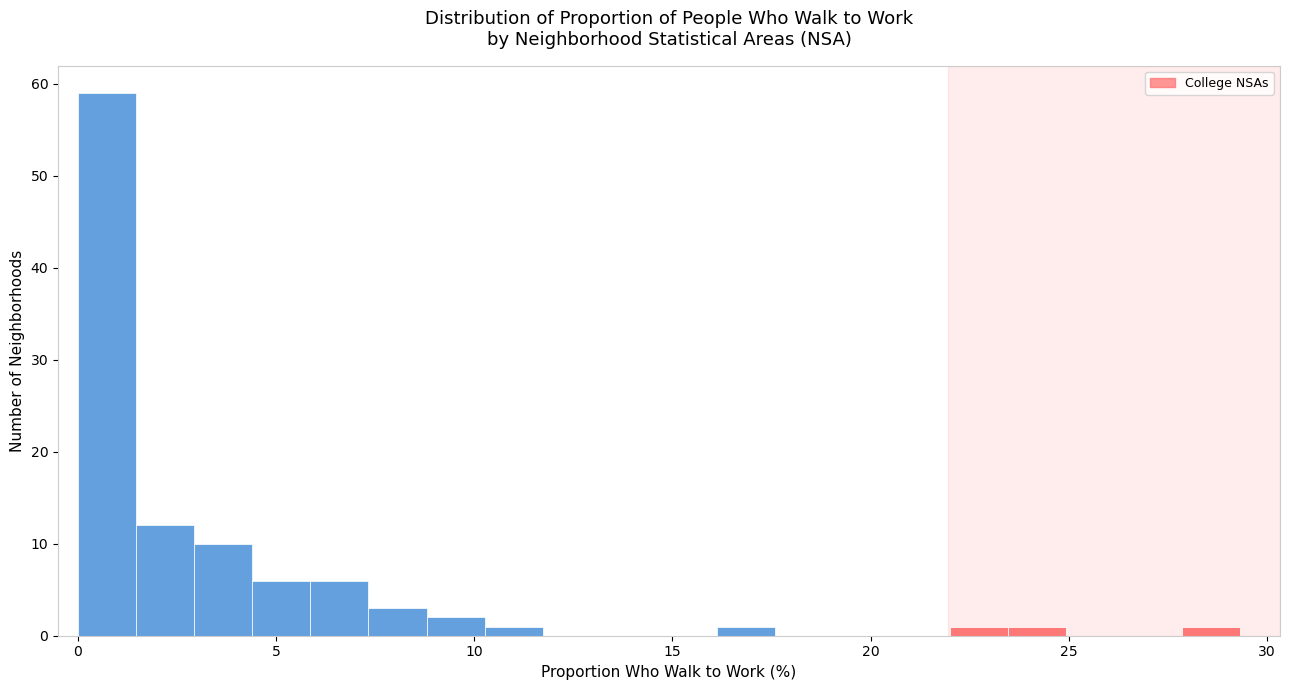

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy import stats

data = NSA_w_demographoics["commute__2"].dropna()

# --- Freedman-Diaconis bin width ---
q75, q25 = np.percentile(data, [75, 25])
iqr = q75 - q25
n = len(data)
h = 2 * iqr / (n ** (1/3))
k = int(np.ceil((data.max() - data.min()) / h))

# --- College values (highest to lowest) ---
college_start = sorted(data)[-3] - h

fig, ax = plt.subplots(figsize=(13, 7))
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

# --- Shade college region ---
ax.axvspan(college_start, data.max() + 1,
           color="#ff6b6b", alpha=0.12, zorder=0)

# --- Main histogram ---
counts, bins, patches = ax.hist(
    data,
    bins=k,
    color="#4a90d9",
    edgecolor="white",
    linewidth=0.6,
    alpha=0.85,
    zorder=2
)

# --- Color college bars red ---
for patch, left_edge in zip(patches, bins[:-1]):
    if left_edge >= college_start:
        patch.set_facecolor("#ff6b6b")
        patch.set_alpha(0.9)



# --- Labels and legend ---
ax.set_title("Distribution of Proportion of People Who Walk to Work\nby Neighborhood Statistical Areas (NSA)",
             fontsize=13, color="black", pad=15)
ax.set_xlabel("Proportion Who Walk to Work (%)", fontsize=11, color="black")
ax.set_ylabel("Number of Neighborhoods", fontsize=11, color="black")
ax.tick_params(colors="black")
for spine in ax.spines.values():
    spine.set_edgecolor("#cccccc")

ax.set_xlim(data.min() - 0.5, data.max() + 1)

college_patch = mpatches.Patch(color="#ff6b6b", alpha=0.7, label="College NSAs")
ax.legend(handles=[
    college_patch,
], facecolor="white", labelcolor="black", fontsize=9, loc="upper right")

plt.tight_layout()
plt.show()

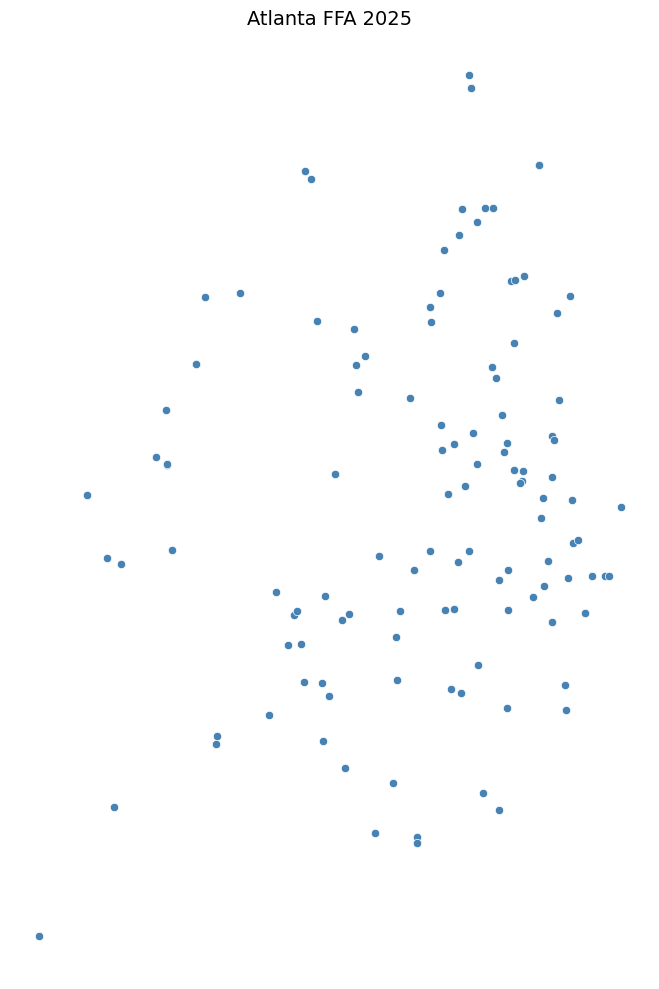

In [3]:
Aglanta = gpd.read_file("data/Aglanta_FFA_2025_ATL_Only.shp")

fig, ax = plt.subplots(figsize=(10, 10))
Aglanta.plot(ax=ax, color='steelblue', edgecolor='white', linewidth=0.5)

ax.set_title("Atlanta FFA 2025", fontsize=14)
ax.set_axis_off()

plt.tight_layout()
plt.show()

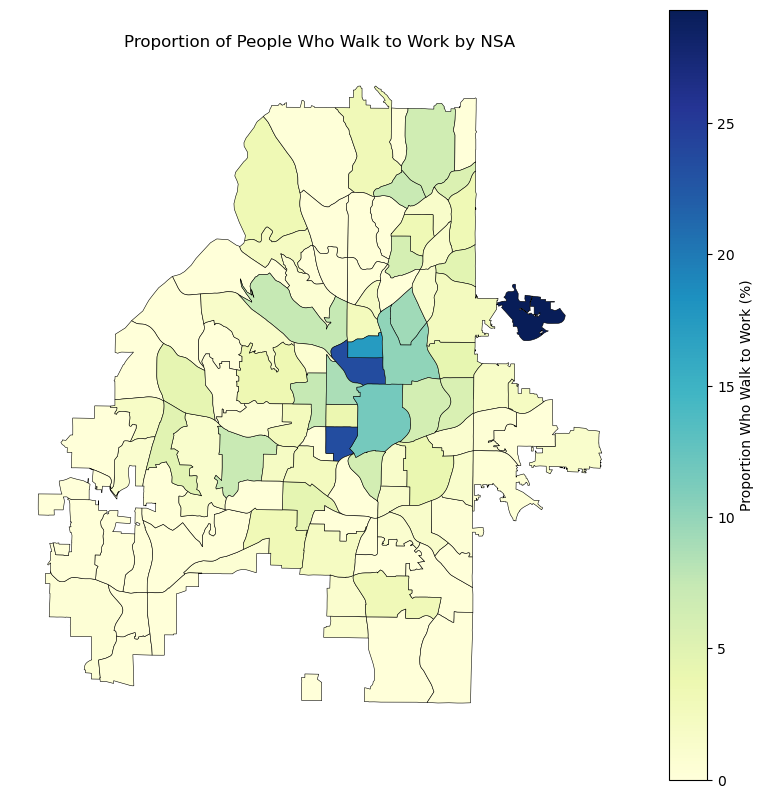

In [6]:
# Plot heatmap of proportion who walk to work
fig, ax = plt.subplots(figsize=(10,10))

NSA_w_demographoics.plot(
    column="commute__2",
    cmap="YlGnBu",        
    legend=True,
    legend_kwds={
        "label": "Proportion Who Walk to Work (%)",
        "orientation": "vertical"
    },
    edgecolor="black",
    linewidth=0.4,
    ax=ax
)

ax.set_title("Proportion of People Who Walk to Work by NSA")
ax.axis("off")

plt.show()

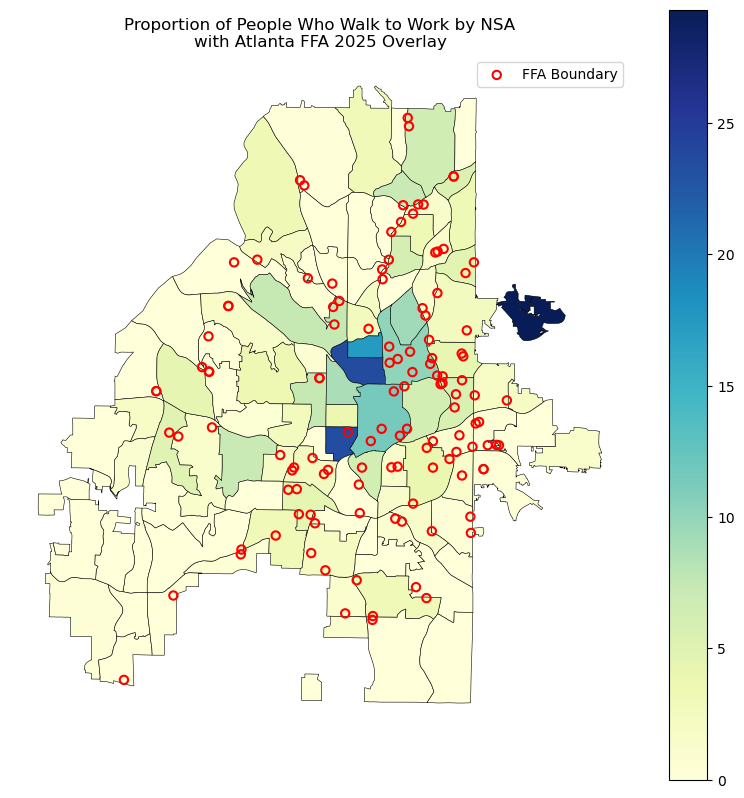

In [5]:
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: NSA choropleth (base layer)
NSA_w_demographoics.plot(
    column="commute__2",
    cmap="YlGnBu",
    legend=True,
    edgecolor="black",
    linewidth=0.4,
    ax=ax
)

# Layer 2: Atlanta FFA overlay — make sure CRS matches first
Aglanta_aligned = Aglanta.to_crs(NSA_w_demographoics.crs)

Aglanta_aligned.plot(
    ax=ax,
    facecolor="none",        # transparent fill so choropleth shows through
    edgecolor="red",
    linewidth=1.5,
    label="FFA Boundary"
)

ax.set_title("Proportion of People Who Walk to Work by NSA\nwith Atlanta FFA 2025 Overlay")
ax.axis("off")
ax.legend()

plt.show()

/var/folders/hk/x84c06k5343fzcmhg4d2vn4h0000gn/T/ipykernel_84136/1892209332.py:42: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
/var/folders/hk/x84c06k5343fzcmhg4d2vn4h0000gn/T/ipykernel_84136/1892209332.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


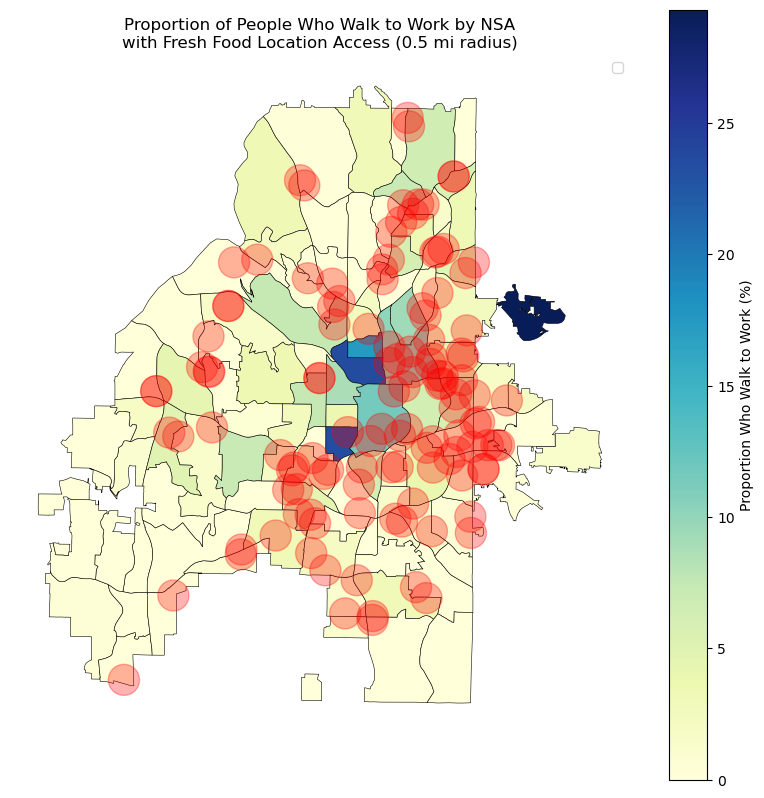

In [8]:
# Reproject to a meter-based CRS, buffer by half a mile, then reproject back
half_mile_meters = 804.672

Aglanta_buffered = (
    Aglanta
    .to_crs(epsg=3857)                        # reproject to meters
    .buffer(half_mile_meters)                  # buffer by 0.5 miles
    .to_frame()                                # convert back to GeoDataFrame
    .rename(columns={0: "geometry"})
    .set_geometry("geometry")
    .set_crs(epsg=3857)
    .to_crs(NSA_w_demographoics.crs)           # reproject back to match NSA layer
)

# Now plot
fig, ax = plt.subplots(figsize=(10, 10))

NSA_w_demographoics.plot(
    column="commute__2",
    cmap="YlGnBu",
    legend=True,
    legend_kwds={
        "label": "Proportion Who Walk to Work (%)",
        "orientation": "vertical"
    },
    edgecolor="black",
    linewidth=0.4,
    ax=ax
)

Aglanta_buffered.plot(
    ax=ax,
    facecolor="red",
    alpha=0.3,               # semi-transparent so choropleth shows through
    edgecolor="red",
    linewidth=1.0,
    label="Fresh Food (0.5 mi radius)"
)

ax.set_title("Proportion of People Who Walk to Work by NSA\nwith Fresh Food Location Access (0.5 mi radius)")
ax.axis("off")
ax.legend()

plt.show()

In [ ]:
import osmnx as ox

# --- Download Atlanta street network ---
G = ox.graph_from_place("Atlanta, Georgia, USA", network_type="drive")
streets = ox.convert.graph_to_gdfs(G, nodes=False, edges=True)
streets = streets.to_crs(NSA_w_demographoics.crs)

# --- Buffer Fresh Food Points ---
half_mile_meters = 804.672

Aglanta_buffered = (
    Aglanta
    .to_crs(epsg=3857)
    .buffer(half_mile_meters)
    .to_frame()
    .rename(columns={0: "geometry"})
    .set_geometry("geometry")
    .set_crs(epsg=3857)
    .to_crs(NSA_w_demographoics.crs)
)

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, 12))

# Layer 1: NSA choropleth
NSA_w_demographoics.plot(
    column="commute__2",
    cmap="YlGnBu",
    legend=True,
    edgecolor="black",
    linewidth=0.4,
    ax=ax
)

# Layer 2: streets
streets.plot(
    ax=ax,
    linewidth=0.3,
    edgecolor="grey",
    alpha=0.5
)

# Layer 3: fresh food buffers
Aglanta_buffered.plot(
    ax=ax,
    facecolor="red",
    alpha=0.3,
    edgecolor="red",
    linewidth=1.0,
    label="Fresh Food (0.5 mi radius)"
)

ax.set_title("Proportion of People Who Walk to Work by NSA\nwith Streets and Fresh Food Access (0.5 mi radius)", fontsize=14)
ax.axis("off")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
cols = NSA_w_demographoics.columns.tolist()
print(cols)


In [ ]:
# Plot heatmap of proportion who walk to work
fig, ax = plt.subplots(figsize=(10,10))

NSA_w_demographoics.plot(
    column="householdi",
    cmap="YlGnBu",        
    legend=True,
    edgecolor="black",
    linewidth=0.4,
    ax=ax
)

ax.set_title("Household Income")
ax.axis("off")

plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 100))

# High walking → low score (inverted)
NSA_w_demographoics["commute_norm"] = 100 - scaler.fit_transform(
    NSA_w_demographoics[["commute__2"]]
)

# High income → high score (NOT inverted)
NSA_w_demographoics["income_norm"] = scaler.fit_transform(
    NSA_w_demographoics[["householdi"]]
)

w_commute = 0.5
w_income  = 0.5

NSA_w_demographoics["vulnerability_score"] = (
    w_commute * NSA_w_demographoics["commute_norm"] +
    w_income  * NSA_w_demographoics["income_norm"]
)

# --- Full vulnerability map ---
fig, ax = plt.subplots(figsize=(10, 10))

NSA_w_demographoics.plot(
    column="vulnerability_score",
    cmap="YlOrRd_r",
    legend=True,
    edgecolor="black",
    linewidth=0.4,
    ax=ax,
    vmin=0,
    vmax=100
)

Aglanta_buffered.plot(
    ax=ax,
    facecolor="blue",
    alpha=0.3,
    edgecolor="blue",
    linewidth=1.0,
    label="Fresh Food (0.5 mi radius)"
)

ax.set_title("Vulnerability Score by NSA (0–100)\n[Lower = More Vulnerable]\nwith Fresh Food Access (0.5 mi radius)", fontsize=14)
ax.axis("off")
ax.legend()
plt.tight_layout()
plt.show()

# --- Top 10 most vulnerable (lowest scores) ---
top10_vulnerable = NSA_w_demographoics.nsmallest(10, "vulnerability_score")

fig, ax = plt.subplots(figsize=(10, 10))

NSA_w_demographoics.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=0.4
)

top10_vulnerable.plot(
    column="vulnerability_score",
    cmap="YlOrRd_r",
    legend=True,
    edgecolor="black",
    linewidth=0.4,
    ax=ax,
    vmin=0,
    vmax=100
)

Aglanta_buffered.plot(
    ax=ax,
    facecolor="blue",
    alpha=0.3,
    edgecolor="blue",
    linewidth=1.0,
    label="Fresh Food (0.5 mi radius)"
)

ax.set_title("Top 10 Most Vulnerable NSAs\n[Lower Score = More Vulnerable]\nwith Fresh Food Access (0.5 mi radius)", fontsize=14)
ax.axis("off")
ax.legend()
plt.tight_layout()
plt.show()

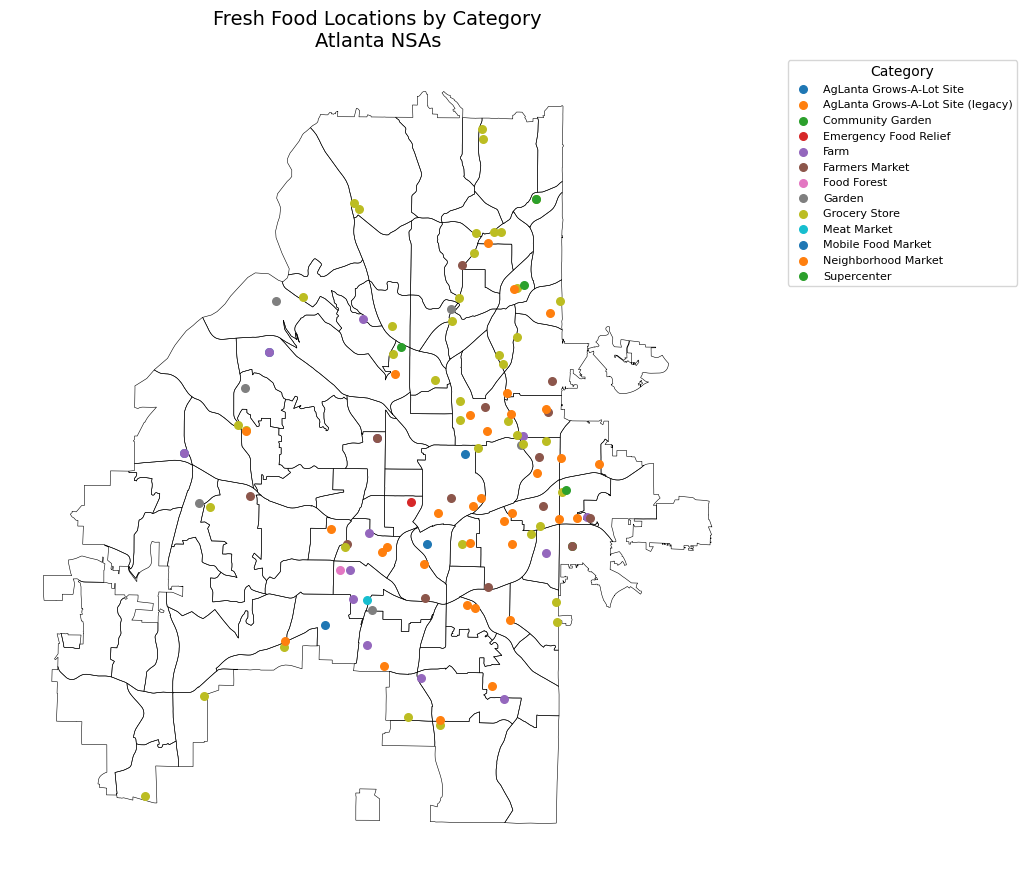

In [3]:
# --- Plot Aglanta points by Category on Atlanta NSA map ---
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Atlanta NSA base map (no fill, just outlines)
NSA_w_demographoics.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4
)

# Layer 2: Aglanta points colored by Category
categories = Aglanta.to_crs(NSA_w_demographoics.crs)
colors = plt.cm.tab10.colors

for i, (category, group) in enumerate(categories.groupby("Category")):
    group.plot(
        ax=ax,
        color=colors[i % len(colors)],
        markersize=30,
        label=category
    )

ax.set_title("Fresh Food Locations by Category\nAtlanta NSAs", fontsize=14)
ax.axis("off")
ax.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

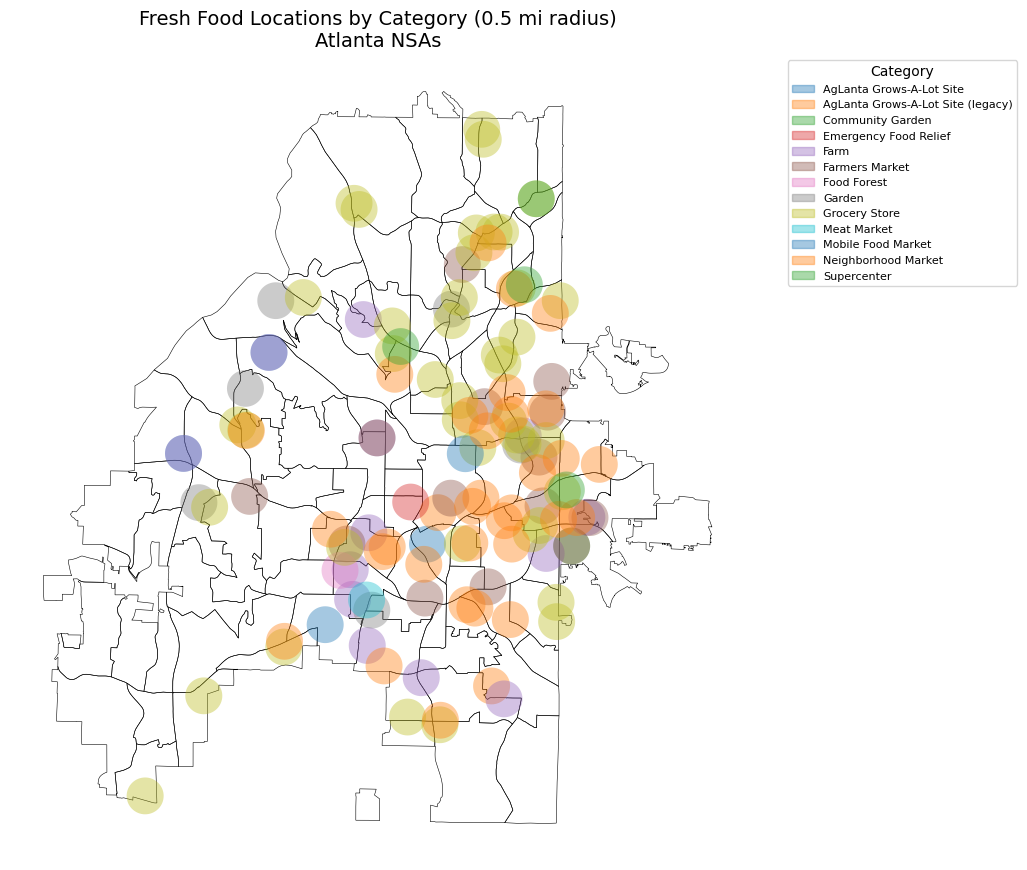

In [5]:
import matplotlib.patches as mpatches

# --- Buffer by 0.5 miles per category ---
Aglanta_cat_buffered = (
    Aglanta
    .to_crs(epsg=3857)
    .assign(geometry=Aglanta.to_crs(epsg=3857).buffer(804.672))
    .to_crs(NSA_w_demographoics.crs)
)

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 10))

# Layer 1: Atlanta NSA base map
NSA_w_demographoics.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4
)

# Layer 2: Buffered circles colored by Category
colors = plt.cm.tab10.colors
legend_patches = []

for i, (category, group) in enumerate(Aglanta_cat_buffered.groupby("Category")):
    color = colors[i % len(colors)]
    group.plot(
        ax=ax,
        color=color,
        alpha=0.4,
    )
    # Manually create a legend patch for each category
    legend_patches.append(
        mpatches.Patch(color=color, alpha=0.4, label=category)
    )

ax.set_title("Fresh Food Locations by Category (0.5 mi radius)\nAtlanta NSAs", fontsize=14)
ax.axis("off")
ax.legend(
    handles=legend_patches,
    title="Category",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [ ]:
import folium
from folium.features import GeoJsonTooltip

# --- Reproject both to WGS84 (lat/lon) since folium requires it ---
Aglanta_wgs = Aglanta.to_crs(epsg=4326)
NSA_wgs = NSA_w_demographoics.to_crs(epsg=4326)

# --- Base map centered on Atlanta ---
m = folium.Map(location=[33.749, -84.388], zoom_start=11, tiles="CartoDB positron")

# --- Layer 1: NSA polygons with tooltip ---
folium.GeoJson(
    NSA_wgs,
    name="Neighborhoods (NSA)",
    style_function=lambda x: {
        "fillColor": "none",
        "color": "black",
        "weight": 0.8,
        "fillOpacity": 0
    },
    tooltip=GeoJsonTooltip(
        fields=["NAME", "population", "commute__2", "householdi"],
        aliases=["Neighborhood:", "Population:", "% Walk to Work:", "Median Household Income:"],
        localize=True,
        sticky=True
    )
).add_to(m)

# --- Layer 2: Aglanta points with tooltip ---
for _, row in Aglanta_wgs.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=8,
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
        tooltip=folium.Tooltip(f"""
            <b>{row.get('Name', 'N/A')}</b><br>
            Category: {row.get('Category', 'N/A')}<br>
            Address: {row.get('Address', 'N/A')}
        """)
    ).add_to(m)

# --- Layer control --
folium.LayerControl().add_to(m)

# --- Display in notebook ---
m

In [ ]:
import folium
from folium.features import GeoJsonTooltip

# --- Reproject to WGS84 ---
Aglanta_wgs = Aglanta.to_crs(epsg=4326)
NSA_wgs = NSA_w_demographoics.to_crs(epsg=4326)

# --- Buffer in meters then reproject to WGS84 ---
Aglanta_buffered_wgs = (
    Aglanta
    .to_crs(epsg=3857)
    .copy()
    .assign(geometry=Aglanta.to_crs(epsg=3857).buffer(804.672))
    .to_crs(epsg=4326)
)

# --- Base map ---
m = folium.Map(location=[33.749, -84.388], zoom_start=11, tiles="CartoDB positron")

# --- Layer 1: NSA outlines only, no tooltip ---
folium.GeoJson(
    NSA_wgs,
    name="Neighborhoods (NSA)",
    style_function=lambda x: {
        "fillColor": "none",
        "color": "black",
        "weight": 0.8,
        "fillOpacity": 0
    }
).add_to(m)

# --- Layer 2: Red buffer circles with tooltip ---
folium.GeoJson(
    Aglanta_buffered_wgs,
    name="Fresh Food (0.5 mi radius)",
    style_function=lambda x: {
        "fillColor": "red",
        "color": "red",
        "weight": 1.5,
        "fillOpacity": 0.3
    },
    tooltip=GeoJsonTooltip(
        fields=["Name", "Category"],
        aliases=["Location:", "Category:"],
        localize=True,
        sticky=False
    )
).add_to(m)

m.save("atlanta_food_map.html")
m

In [3]:
import folium
from folium.features import GeoJsonTooltip
import branca.colormap as cm

# --- Reproject to WGS84 ---
NSA_wgs = NSA_w_demographoics.to_crs(epsg=4326)

# --- Buffer in meters then reproject to WGS84 ---
Aglanta_buffered_wgs = (
    Aglanta
    .to_crs(epsg=3857)
    .copy()
    .assign(geometry=Aglanta.to_crs(epsg=3857).buffer(804.672))
    .to_crs(epsg=4326)
)

# --- Colormap for walking proportion ---
colormap = cm.linear.YlGnBu_09.scale(
    NSA_wgs["commute__2"].min(),
    NSA_wgs["commute__2"].max()
)
colormap.caption = "Proportion Who Walk to Work"

# --- Base map ---
m = folium.Map(location=[33.749, -84.388], zoom_start=11, tiles="CartoDB positron")

# --- Layer 1: NSA colored by walking proportion ---
folium.GeoJson(
    NSA_wgs,
    name="Walk to Work Proportion",
    style_function=lambda x: {
        "fillColor": colormap(x["properties"]["commute__2"])
                     if x["properties"]["commute__2"] is not None
                     else "grey",
        "color": "black",
        "weight": 0.8,
        "fillOpacity": 0.6
    }
).add_to(m)

# --- Add colormap legend ---
colormap.add_to(m)

# --- Layer 2: Red buffer circles with tooltip ---
folium.GeoJson(
    Aglanta_buffered_wgs,
    name="Fresh Food (0.5 mi radius)",
    style_function=lambda x: {
        "fillColor": "red",
        "color": "red",
        "weight": 1.5,
        "fillOpacity": 0.3
    },
    tooltip=GeoJsonTooltip(
        fields=["Name", "Category"],
        aliases=["Location:", "Category:"],
        localize=True,
        sticky=False
    )
).add_to(m)

folium.LayerControl().add_to(m)

m.save("atlanta_food_map.html")
m